<div style="background-color: #e7f3fe; border-left: 6px solid #2196F3; padding: 12px; border-radius: 4px; margin-bottom: 10px;">
    <p style="margin: 0; color: #0c5460; font-family: sans-serif;"><b>

# Task 1 — Exploratory Data Analysis (EDA)
## Public diabetes progression dataset

**Objective:** profile a public dataset, make transparent cleaning decisions, explore distributions and relationships, and communicate evidence-based observations.

### Dataset and scope
- **Source:** scikit-learn's `load_diabetes` dataset, based on a public diabetes study dataset.
- **Rows:** 442 participants; **predictors:** 10 baseline variables; **target:** a quantitative measure of disease progression one year after baseline.
- **Important interpretation note:** predictor columns are already mean-centered and scaled by the dataset provider. Their values are not raw units (for example, `bmi` is a standardized BMI-related measure). The target is kept on its dataset-provided scale.
- **Purpose:** descriptive exploration only. This dataset is not used here to diagnose people or make clinical recommendations.

### Reproducibility
Run the notebook from top to bottom. The CSV is included beside this notebook, so the analysis does not require downloading data at runtime. The `visualizations/` directory contains high-resolution exports of the key figures.</p>
</div>

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = Path("diabetes_eda_dataset.csv")
OUT_DIR = Path("visualizations")
OUT_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook", palette="viridis")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 220, "axes.titlesize": 14})

df = pd.read_csv(DATA_PATH)
print(f"Loaded dataset: {DATA_PATH.resolve()}")
print(f"Shape: {df.shape[0]} rows × {df.shape[1]} columns")
df.head()

Loaded dataset: C:\Users\chira\CodeNova\Task_1\diabetes_eda_dataset.csv
Shape: 442 rows × 11 columns


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


<div style="background-color: #e7f3fe; border-left: 6px solid #2196F3; padding: 12px; border-radius: 4px; margin-bottom: 10px;">
    <p style="margin: 0; color: #0c5460; font-family: sans-serif;"><b>## 1. Initial profiling

We first inspect dimensions, data types, descriptive statistics, missingness, and duplicate records. This establishes whether any cleaning is actually necessary rather than assuming problems exist.</p>
</div>

In [3]:
print("Shape:", df.shape)
print("\\nData types:")
display(df.dtypes.rename("dtype").to_frame())
print("\\nDescriptive statistics:")
display(df.describe().T.round(3))

Shape: (442, 11)
\nData types:


,dtype
age,float64
sex,float64
bmi,float64
bp,float64
s1,float64
s2,float64
s3,float64
s4,float64
s5,float64
s6,float64


\nDescriptive statistics:


,count,mean,std,min,25%,50%,75%,max
age,442.0,-0.000,0.048,-0.107,-0.037,0.005,0.038,0.111
sex,442.0,0.000,0.048,-0.045,-0.045,-0.045,0.051,0.051
bmi,442.0,-0.000,0.048,-0.090,-0.034,-0.007,0.031,0.171
bp,442.0,-0.000,0.048,-0.112,-0.037,-0.006,0.036,0.132
s1,442.0,-0.000,0.048,-0.127,-0.034,-0.004,0.028,0.154
s2,442.0,0.000,0.048,-0.116,-0.030,-0.004,0.030,0.199
s3,442.0,0.000,0.048,-0.102,-0.035,-0.007,0.029,0.181
s4,442.0,0.000,0.048,-0.076,-0.039,-0.003,0.034,0.185
s5,442.0,0.000,0.048,-0.126,-0.033,-0.002,0.032,0.134
s6,442.0,0.000,0.048,-0.138,-0.033,-0.001,0.028,0.136


In [4]:
profile = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(),
})
display(profile)
print(f"Total missing cells: {int(df.isna().sum().sum())}")
print(f"Duplicate rows: {int(df.duplicated().sum())}")

,dtype,missing_count,missing_pct,unique_values
age,float64,0,0.0,58
sex,float64,0,0.0,2
bmi,float64,0,0.0,163
bp,float64,0,0.0,100
s1,float64,0,0.0,141
s2,float64,0,0.0,302
s3,float64,0,0.0,63
s4,float64,0,0.0,66
s5,float64,0,0.0,184
s6,float64,0,0.0,56


Total missing cells: 0
Duplicate rows: 0


<div style="background-color: #e7f3fe; border-left: 6px solid #2196F3; padding: 12px; border-radius: 4px; margin-bottom: 10px;">
    <p style="margin: 0; color: #0c5460; font-family: sans-serif;"><b>### Profiling interpretation
- The dataset contains numeric predictors and one numeric target, which makes summary statistics, correlations, and pairwise plots appropriate.
- Missing values and exact duplicate rows are counted explicitly below.
- Because this dataset's predictors are pre-scaled, distributions are interpreted as standardized values—not raw measurements.</p>
</div>

<div style="background-color: #e7f3fe; border-left: 6px solid #2196F3; padding: 12px; border-radius: 4px; margin-bottom: 10px;">
    <p style="margin: 0; color: #0c5460; font-family: sans-serif;"><b><h3>## 2. Data quality and cleaning decisions</h3>

### Missing values
If missing values existed in a numeric feature, median imputation would be a robust baseline because the median is less sensitive to extreme values than the mean. Dropping rows would be considered only if missingness were limited and plausibly non-informative. **No imputation is applied unless missing values are found.**

### Duplicate rows
Exact duplicate records are counted. A duplicate is not automatically removed unless it is an exact repeated row and the data's sampling design does not indicate that repeated observations are meaningful.

### Outliers: 1.5 × IQR screening
For each numeric column, define `IQR = Q3 − Q1`; flag values below `Q1 − 1.5 × IQR` or above `Q3 + 1.5 × IQR`. This is a screening rule, not proof of an error. Since observations can be valid extremes, flagged values are retained unless there is independent evidence of a data-entry or measurement problem.</p>
</div>

In [14]:
# Work on a separate copy so the original CSV remains unchanged.
clean_df = df.copy()

# Conditional numeric median imputation: only runs if missing values are present.
numeric_cols = clean_df.select_dtypes(include="number").columns.tolist()
missing_before = int(clean_df[numeric_cols].isna().sum().sum())
if missing_before:
    medians = clean_df[numeric_cols].median()
    clean_df[numeric_cols] = clean_df[numeric_cols].fillna(medians)
    print(f"Median-imputed {missing_before} missing numeric cells.")
else:
    print("No missing numeric cells found; no imputation required.")

# Remove exact duplicates only if present; report the count.
duplicates_before = int(clean_df.duplicated().sum())
if duplicates_before:
    clean_df = clean_df.drop_duplicates().reset_index(drop=True)
print(f"Exact duplicate rows found: {duplicates_before}; rows after duplicate check: {len(clean_df)}")

# IQR flags: record counts but retain observations pending domain validation.
iqr_rows = []
for col in clean_df.select_dtypes(include="number").columns:
    q1, q3 = clean_df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (clean_df[col] < lower) | (clean_df[col] > upper)
    iqr_rows.append({
        "feature": col, "Q1": q1, "Q3": q3, "IQR": iqr,
        "lower_fence": lower, "upper_fence": upper,
        "flagged_values": int(mask.sum())
    })
iqr_report = pd.DataFrame(iqr_rows).sort_values("flagged_values", ascending=False)
display(iqr_report.round(3))
print("Cleaning policy: retain IQR-flagged values unless independently verified as errors.")
df.to_csv("cleaned_diabetes_dataset.csv", index=False)

print("Cleaned dataset saved successfully!")

No missing numeric cells found; no imputation required.
Exact duplicate rows found: 0; rows after duplicate check: 442


,feature,Q1,Q3,IQR,lower_fence,upper_fence,flagged_values
9,s6,-0.033,0.028,0.061,-0.125,0.120,9
4,s1,-0.034,0.028,0.063,-0.128,0.122,8
6,s3,-0.035,0.029,0.064,-0.132,0.126,7
5,s2,-0.030,0.030,0.060,-0.121,0.120,7
8,s5,-0.033,0.032,0.066,-0.132,0.131,4
7,s4,-0.039,0.034,0.074,-0.150,0.145,4
2,bmi,-0.034,0.031,0.065,-0.132,0.129,3
1,sex,-0.045,0.051,0.095,-0.188,0.194,0
0,age,-0.037,0.038,0.075,-0.150,0.151,0
3,bp,-0.037,0.036,0.072,-0.145,0.144,0


Cleaning policy: retain IQR-flagged values unless independently verified as errors.
Cleaned dataset saved successfully!


<div style="background-color: #e7f3fe; border-left: 6px solid #2196F3; padding: 12px; border-radius: 4px; margin-bottom: 10px;">
    <h3 style="margin: 0; color: #0c5460; font-family: sans-serif;"><b>## 3. Univariate analysis — target and feature distributions</h3>
    </div>

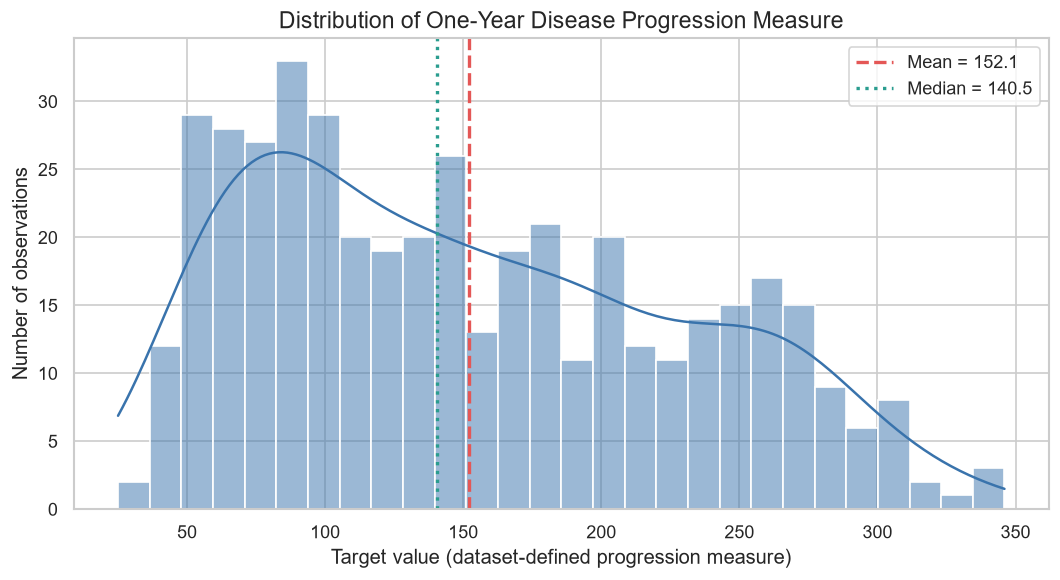

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(clean_df["target"], kde=True, bins=28, ax=ax, color="#3973ac")
ax.axvline(clean_df["target"].mean(), color="#e45756", linestyle="--", linewidth=2,
           label=f"Mean = {clean_df['target'].mean():.1f}")
ax.axvline(clean_df["target"].median(), color="#2a9d8f", linestyle=":", linewidth=2,
           label=f"Median = {clean_df['target'].median():.1f}")
ax.set(title="Distribution of One-Year Disease Progression Measure",
       xlabel="Target value (dataset-defined progression measure)", ylabel="Number of observations")
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "01_target_distribution.png", bbox_inches="tight")
plt.show()

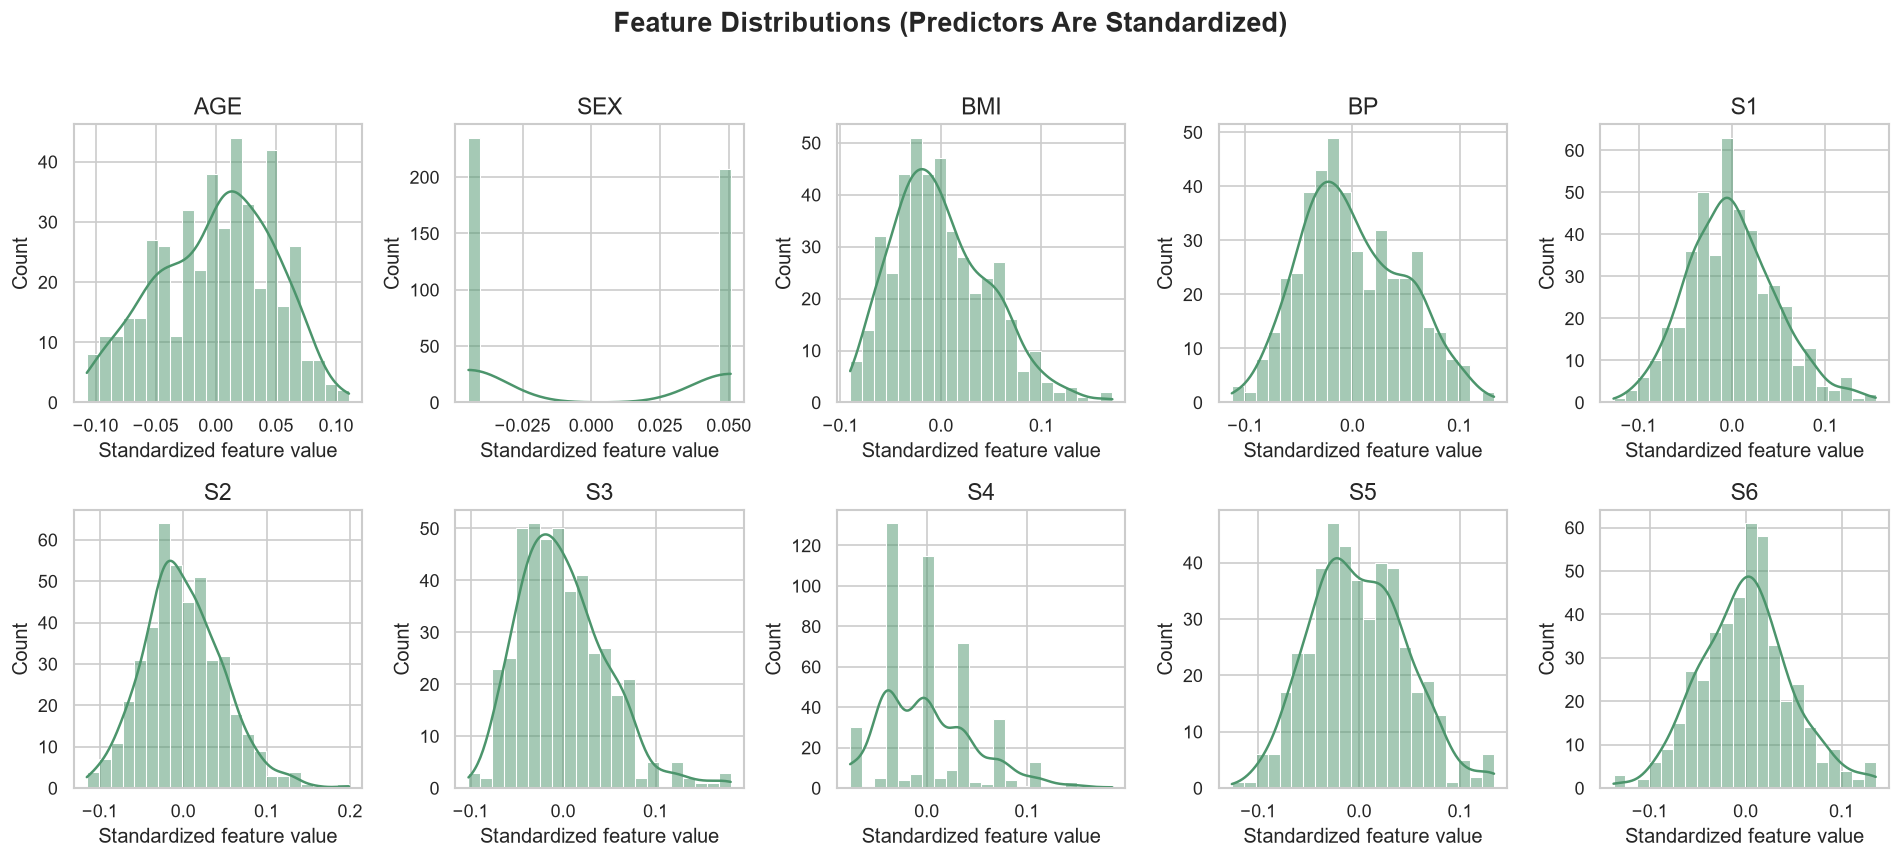

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for ax, col in zip(axes.flat, [c for c in clean_df.columns if c != "target"]):
    sns.histplot(clean_df[col], kde=True, bins=22, ax=ax, color="#4c956c")
    ax.set_title(col.upper())
    ax.set_xlabel("Standardized feature value")
    ax.set_ylabel("Count")
fig.suptitle("Feature Distributions (Predictors Are Standardized)", y=1.02, fontsize=16, fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "02_feature_distributions.png", bbox_inches="tight")
plt.show()

<div style="background-color: #e7f3fe; border-left: 6px solid #2196F3; padding: 12px; border-radius: 4px; margin-bottom: 10px;">
    <p style="margin: 0; color: #0c5460; font-family: sans-serif;"><b>### Distribution observations
- Compare the target's mean and median to assess whether the distribution may be asymmetric.
- Feature distributions differ in spread and shape despite the provider's scaling; scaling does not make every feature normally distributed.
- Histograms are descriptive. They do not establish causation or clinical significance.</p>
    </div>

<div style="background-color: #e7f3fe; border-left: 6px solid #2196F3; padding: 12px; border-radius: 4px; margin-bottom: 10px;">
    <p style="margin: 0; color: #0c5460; font-family: sans-serif;"><b><h3>## 4. Correlation analysis </h3>

Pearson correlation summarizes the direction and strength of **linear** association. Correlation does not establish causation and can miss nonlinear relationships.</p>
</div>

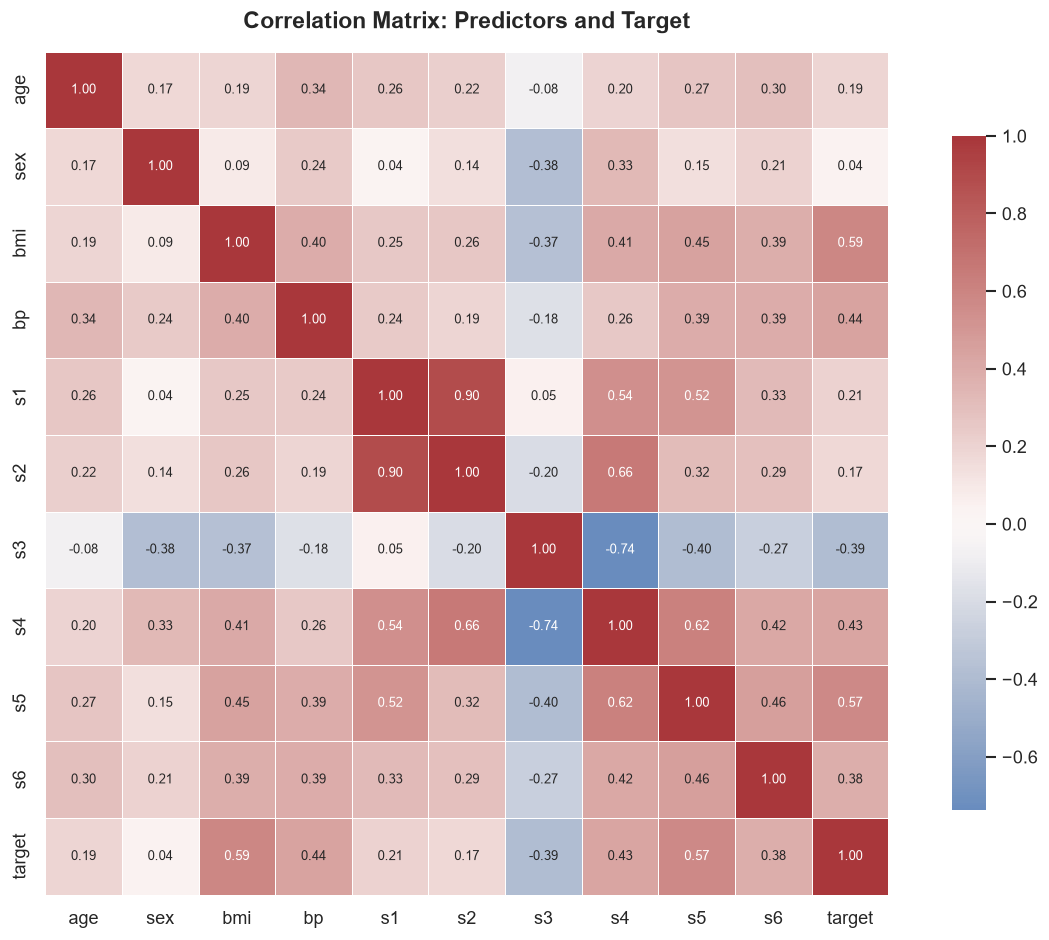

,pearson_r_with_target
bmi,0.586
s5,0.566
bp,0.441
s4,0.430
s3,-0.395
s6,0.382
s1,0.212
age,0.188
s2,0.174
sex,0.043


In [8]:
corr = clean_df.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(corr, cmap="vlag", center=0, annot=True, fmt=".2f", square=True,
            linewidths=.4, cbar_kws={"shrink": .8}, ax=ax, annot_kws={"size": 8})
ax.set_title("Correlation Matrix: Predictors and Target", pad=14, fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "03_correlation_heatmap.png", bbox_inches="tight")
plt.show()

target_corr = corr["target"].drop("target").sort_values(key=lambda s: s.abs(), ascending=False)
display(target_corr.rename("pearson_r_with_target").to_frame().round(3))

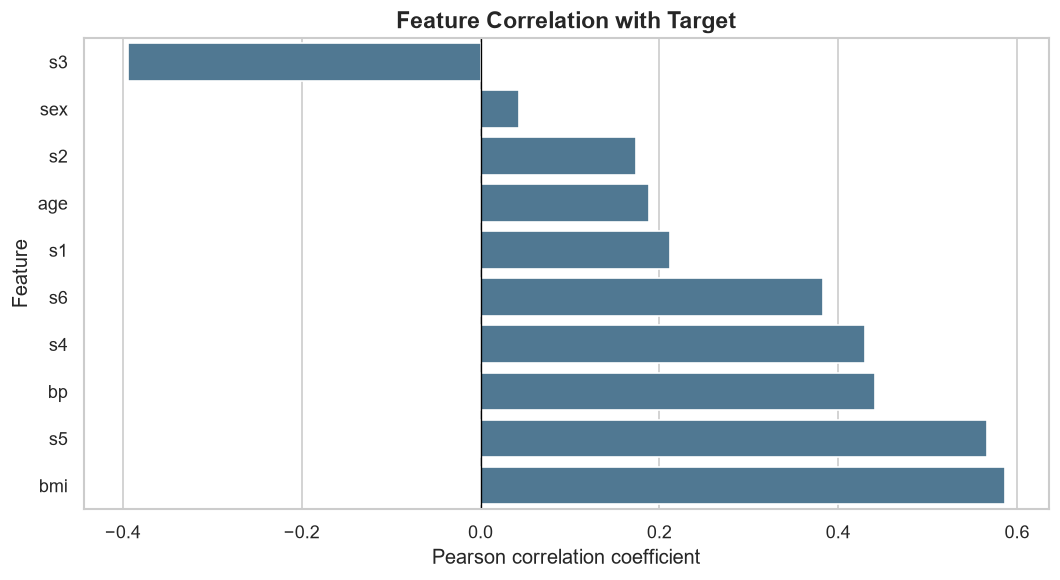

In [9]:
ranked = target_corr.sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=ranked.values, y=ranked.index, ax=ax, color="#457b9d")
ax.axvline(0, color="black", linewidth=.8)
ax.set_title("Feature Correlation with Target", fontweight="bold")
ax.set_xlabel("Pearson correlation coefficient")
ax.set_ylabel("Feature")
fig.tight_layout()
fig.savefig(OUT_DIR / "06_target_correlation_ranking.png", bbox_inches="tight")
plt.show()

<div style="background-color: #e7f3fe; border-left: 6px solid #2196F3; padding: 12px; border-radius: 4px; margin-bottom: 10px;">
    <h3 style="margin: 0; color: #0c5460; font-family: sans-serif;"><b>## 5. Outlier visualization</h3>
    </div>

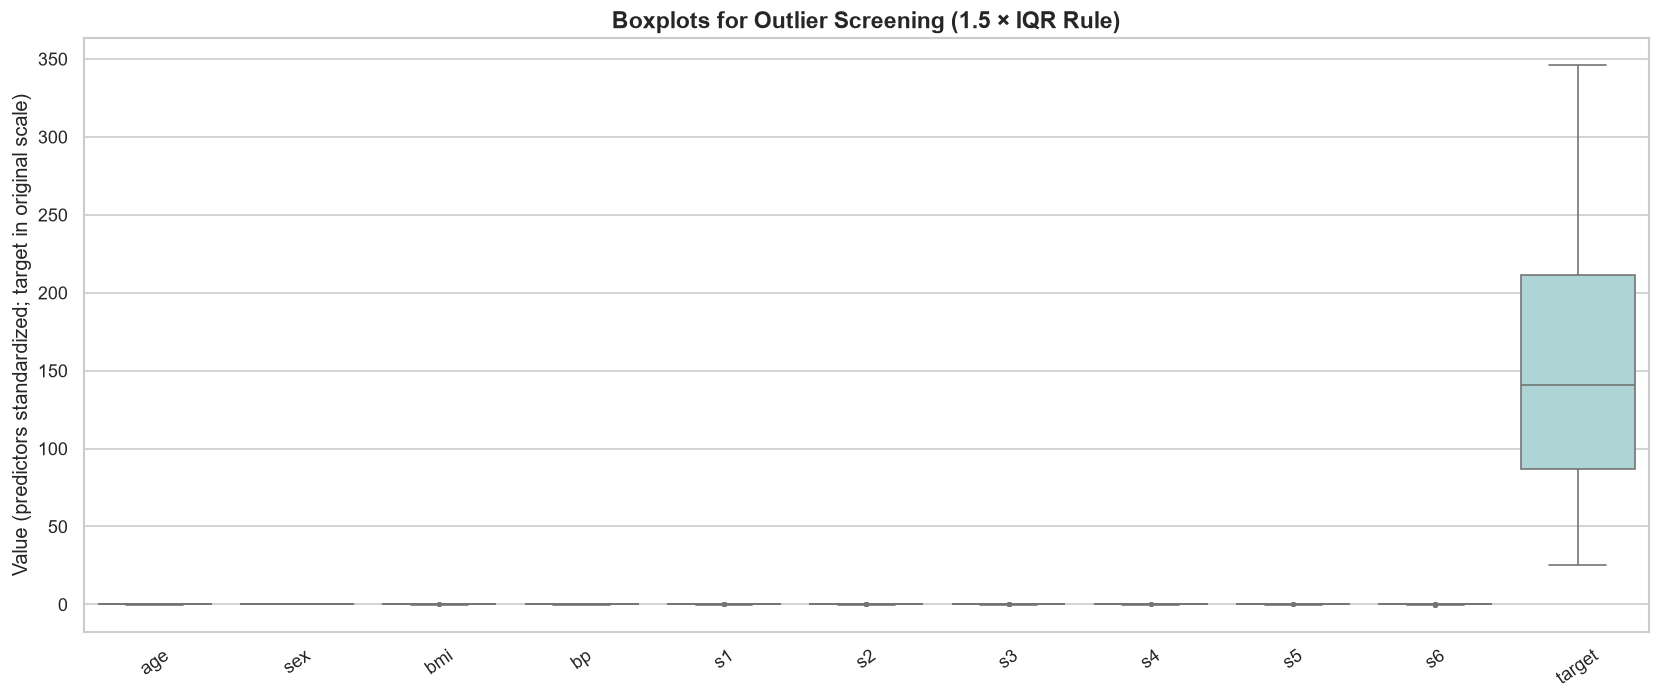

In [10]:
box_df = clean_df.melt(var_name="Variable", value_name="Value")
fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(data=box_df, x="Variable", y="Value", ax=ax, color="#a8dadc", fliersize=2)
ax.set_title("Boxplots for Outlier Screening (1.5 × IQR Rule)", fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("Value (predictors standardized; target in original scale)")
ax.tick_params(axis="x", rotation=35)
fig.tight_layout()
fig.savefig(OUT_DIR / "04_boxplots_iqr.png", bbox_inches="tight")
plt.show()

<div style="background-color: #e7f3fe; border-left: 6px solid #2196F3; padding: 12px; border-radius: 4px; margin-bottom: 10px;">
    <p style="margin: 0; color: #0c5460; font-family: sans-serif;"><b>### Outlier decision
Boxplots help locate observations beyond the IQR fences, but the target is an outcome measure and predictor values are standardized. Removing flagged rows solely to make plots look cleaner could bias the dataset and distort real variation. Therefore, this analysis **flags but retains** them. If this were a production project, flagged records would be checked against source documentation before any correction or exclusion.</p>
    </div>

<div style="background-color: #e7f3fe; border-left: 6px solid #2196F3; padding: 12px; border-radius: 4px; margin-bottom: 10px;">
    <p style="margin: 0; color: #0c5460; font-family: sans-serif;"><b><h3>## 6. Pairwise scatter plots</h3>

The following plots focus on the four predictors with the strongest absolute Pearson correlations with the target. A smooth trend is overlaid to help reveal broad patterns; it should not be interpreted as a causal effect.</p>
</div>

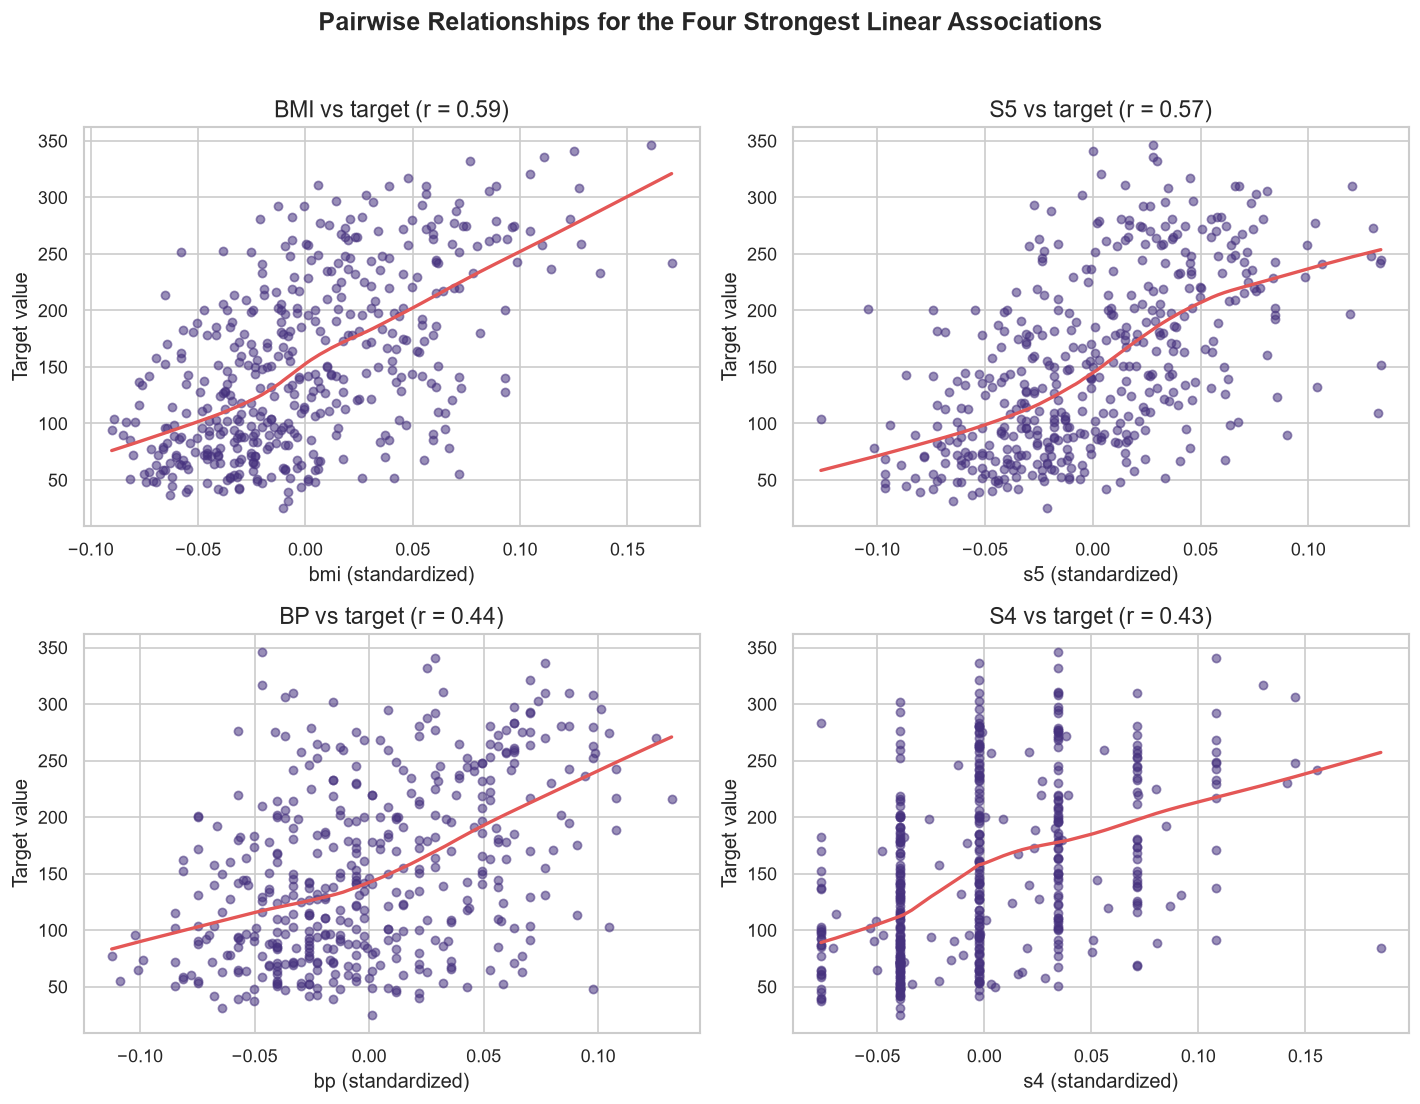

In [11]:
top_features = target_corr.head(4).index.tolist()
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, col in zip(axes.flat, top_features):
    r = clean_df[col].corr(clean_df["target"])
    sns.regplot(data=clean_df, x=col, y="target", lowess=True,
                scatter_kws={"alpha": .55, "s": 24},
                line_kws={"color": "#e45756", "linewidth": 2}, ax=ax)
    ax.set_title(f"{col.upper()} vs target (r = {r:.2f})")
    ax.set_xlabel(f"{col} (standardized)")
    ax.set_ylabel("Target value")
fig.suptitle("Pairwise Relationships for the Four Strongest Linear Associations",
             y=1.02, fontsize=15, fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "05_pairwise_scatterplots.png", bbox_inches="tight")
plt.show()

<div style="background-color: #e7f3fe; border-left: 6px solid #2196F3; padding: 12px; border-radius: 4px; margin-bottom: 10px;">
    <p style="margin: 0; color: #0c5460; font-family: sans-serif;"><b>## 7. Evidence-based findings

The code below creates findings from the observed data, avoiding generic claims. Treat effect sizes as descriptive associations within this dataset.</p>
</div>

In [12]:
print(f"Dataset size: {clean_df.shape[0]} rows × {clean_df.shape[1]} columns.")
print(f"Missing cells in original data: {int(df.isna().sum().sum())}.")
print(f"Exact duplicate rows in original data: {int(df.duplicated().sum())}.")
print(f"Target mean: {clean_df['target'].mean():.2f}; median: {clean_df['target'].median():.2f}; "
      f"standard deviation: {clean_df['target'].std():.2f}.")
print("\\nThree strongest absolute linear correlations with target:")
for feature, r in target_corr.head(3).items():
    print(f"  • {feature}: r = {r:.3f}")
print("\\nTwo weakest absolute linear correlations with target:")
for feature, r in target_corr.tail(2).items():
    print(f"  • {feature}: r = {r:.3f}")
print("\\nIQR screening:")
for _, row in iqr_report.sort_values("flagged_values", ascending=False).iterrows():
    if row["flagged_values"] > 0:
        print(f"  • {row['feature']}: {int(row['flagged_values'])} value(s) beyond 1.5×IQR fences")
print("Note: IQR flags are screening signals, not automatic removal criteria.")

Dataset size: 442 rows × 11 columns.
Missing cells in original data: 0.
Exact duplicate rows in original data: 0.
Target mean: 152.13; median: 140.50; standard deviation: 77.09.
\nThree strongest absolute linear correlations with target:
  • bmi: r = 0.586
  • s5: r = 0.566
  • bp: r = 0.441
\nTwo weakest absolute linear correlations with target:
  • s2: r = 0.174
  • sex: r = 0.043
\nIQR screening:
  • s6: 9 value(s) beyond 1.5×IQR fences
  • s1: 8 value(s) beyond 1.5×IQR fences
  • s3: 7 value(s) beyond 1.5×IQR fences
  • s2: 7 value(s) beyond 1.5×IQR fences
  • s5: 4 value(s) beyond 1.5×IQR fences
  • s4: 4 value(s) beyond 1.5×IQR fences
  • bmi: 3 value(s) beyond 1.5×IQR fences
Note: IQR flags are screening signals, not automatic removal criteria.


<div style="background-color: #e7f3fe; border-left: 6px solid #2196F3; padding: 12px; border-radius: 4px; margin-bottom: 10px;">
    <p style="margin: 0; color: #0c5460; font-family: sans-serif;"><b>## 8. Practical implications and limitations

### Practical takeaways
1. Prioritize the predictors with the strongest observed associations for follow-up exploration, not as automatic causal drivers.
2. Use scatter plots to check whether a single correlation coefficient hides curvature or clusters.
3. Keep a documented cleaning trail: no missingness means no imputation is needed; IQR flags alone do not justify deletion.
4. Before modeling, split data appropriately and fit any preprocessing only on the training split to avoid leakage. This notebook is EDA, not a predictive model.

### Limitations
- The dataset is relatively small (442 rows) and originates from a specific study context.
- Predictors are preprocessed/standardized, so values should not be read as raw clinical measurements.
- Associations may be affected by confounding and do not prove cause and effect.
- Findings should not be generalized to individuals or used for diagnosis or treatment decisions.

## 9. Conclusion

This EDA profiles the dataset, documents missingness and duplicates, applies a conditional cleaning policy, screens outliers using the 1.5×IQR rule, and explores distributions, correlations, and pairwise relationships. The strongest associations are reported from the computed values, while potentially valid extreme observations are retained pending independent verification.

**Deliverables:** executed notebook, local CSV, high-resolution visualization exports, and a README with reproduction instructions.</p>
</div>